# Matplotlib for Data Analysts

A hands-on, practical guide to essential data visualization with **Matplotlib** and **Pandas**.

### Learning Objectives:
1. **Basic Line Plots**: Plotting coordinate pairs, customizing markers, colors, and grids.
2. **DataFrame Visualization**: Directly plotting Pandas columns and Series.
3. **Distribution Analysis**: Plotting **Histograms** to understand data spread and skewness.
4. **Outlier Detection**: Using **Box Plots** to spot extreme anomalies and cleaning them.
5. **Categorical Data**: Visualizing distributions using **Pie Charts** and **Bar Charts**.
6. **Bivariate Analysis**: Examining relationships between continuous variables with **Scatter Plots** and sorted trend lines.


In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. Basic Line Plots
Visualizing basic coordinate pairs $(x, y)$ using `plt.plot()` and rendering with `plt.show()`.


In [2]:
x=[1,4,5]
y=[2,4,5]

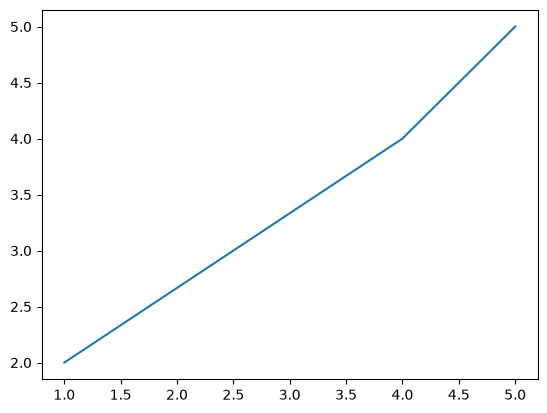

In [3]:
plt.plot(x,y)
plt.show()

## 2. Visualizing Pandas DataFrames
Plotting numerical columns directly from a DataFrame with custom line color (`color="red"`), star markers (`marker="*"`), and background grid lines (`plt.grid()`).


In [4]:
data ={
    "Salary":[200,400,500,300,600,450,988,345,876,567]
}

In [5]:
df =pd.DataFrame(data)
df

,Salary
0,200
1,400
2,500
3,300
4,600
5,450
6,988
7,345
8,876
9,567


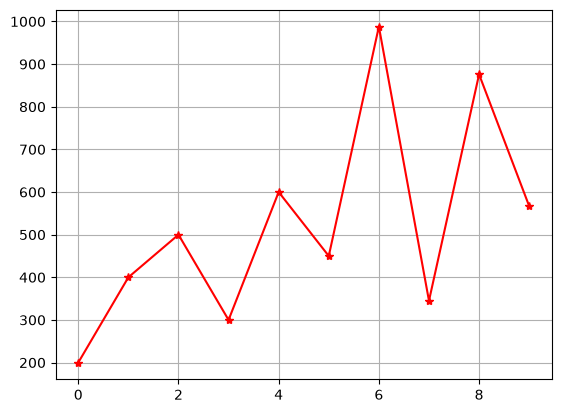

In [6]:
plt.plot(df["Salary"],color="red",marker="*")
plt.grid()
plt.show()

## 3. Frequency Distribution: Histograms
Histograms group numerical data into discrete bins (intervals) to display frequency distribution, spread, and modal clusters.


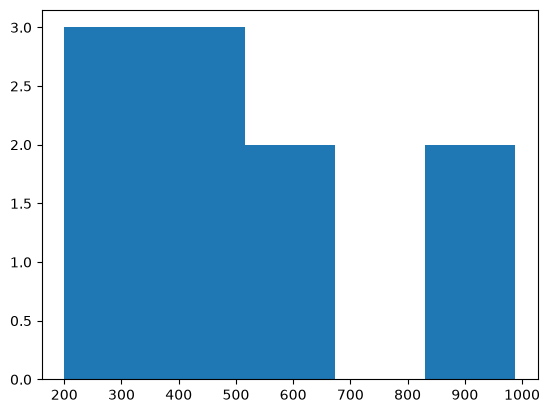

In [7]:
# histogram
plt.hist(df["Salary"],bins=5)
plt.show()

## 4. Outlier Detection with Box Plots
A Box Plot (box-and-whisker plot) summarizes numerical data using a 5-number summary (Min, Q1, Median, Q3, Max) and clearly flags potential outliers beyond the whiskers.


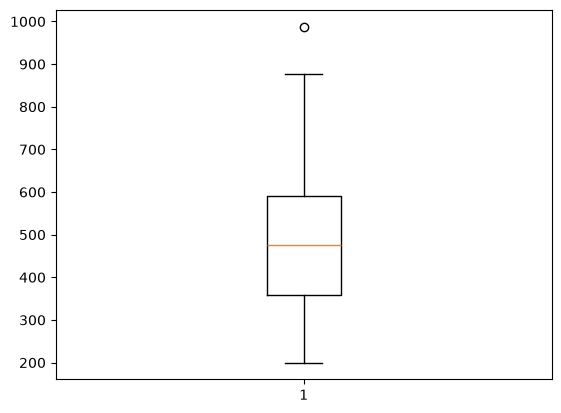

In [8]:
plt.boxplot(df['Salary'])
plt.show()

### Simulating an Outlier
Injecting an extreme salary value (`50,000`) into index 9 to observe how extreme values distort the scale of a box plot.


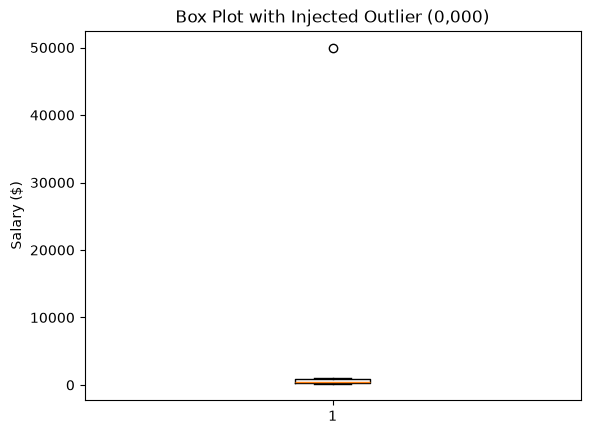

In [9]:
# Simulating an outlier in a copy to observe boxplot distortion
df_outlier = df.copy()
df_outlier.loc[9, "Salary"] = 50000
plt.boxplot(df_outlier['Salary'])
plt.title("Box Plot with Injected Outlier (0,000)")
plt.ylabel("Salary ($)")
plt.show()

### Cleaning & Dropping Outliers
Removing the outlier record to restore clean distribution for subsequent analyses.


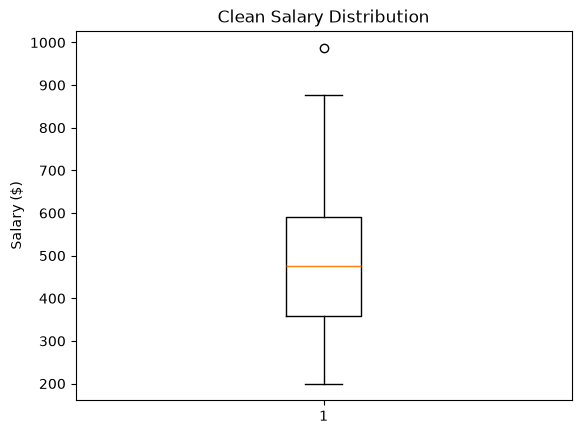

In [10]:
# Clean salary distribution baseline
plt.boxplot(df['Salary'])
plt.title("Clean Salary Distribution")
plt.ylabel("Salary ($)")
plt.show()

In [11]:
df

,Salary
0,200
1,400
2,500
3,300
4,600
5,450
6,988
7,345
8,876
9,567


## 5. Categorical Data Analysis
Adding department categories and aggregating counts with `value_counts()` to compare categorical representations.


In [12]:
df["Dept"]=["IT","Management","Law","Business","Marketing"]*2


In [13]:
df.head()

,Salary,Dept
0,200,IT
1,400,Management
2,500,Law
3,300,Business
4,600,Marketing


In [14]:
# count
count = df['Dept'].value_counts()
count

Dept
IT            2
Management    2
Law           2
Business      2
Marketing     2
Name: count, dtype: int64

### Visualizing Proportions: Pie Chart
Pie charts display percentage shares of each category using `autopct="%1.1f"`.


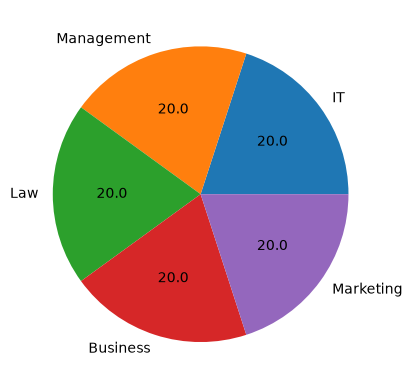

In [15]:
plt.pie(count,labels=count.index, autopct="%1.1f")
plt.show()

### Visualizing Counts: Bar Chart
Bar charts provide clearer side-by-side magnitude comparisons across categories.


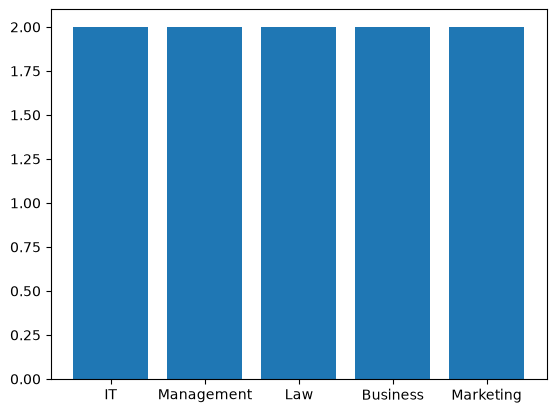

In [16]:
# counter plot

plt.bar(count.index,count)
plt.show()

## 6. Bivariate Analysis & Correlation
Comparing two numerical variables (`Age` vs `Salary`) to uncover patterns, trends, or relationships.


In [17]:
df['Age']=[32,45,65,76,34,56,78,98,12,24]

In [18]:
df

,Salary,Dept,Age
0,200,IT,32
1,400,Management,45
2,500,Law,65
3,300,Business,76
4,600,Marketing,34
5,450,IT,56
6,988,Management,78
7,345,Law,98
8,876,Business,12
9,567,Marketing,24


### Scatter Plot: Age vs Salary
Plotting points along the $(x, y)$ coordinate plane to observe point clustering or dispersion.


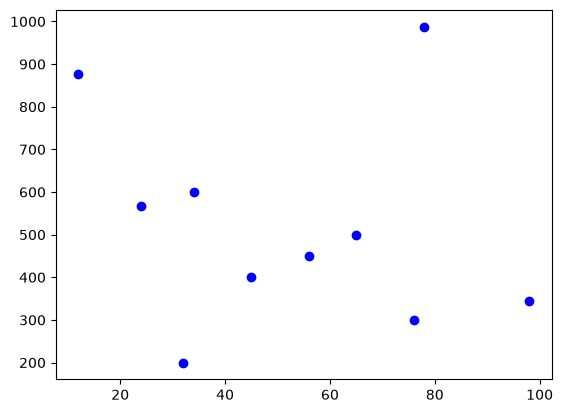

In [19]:
# scatter plot
plt.scatter(df['Age'],df['Salary'],color="blue")
plt.show()

### Sorted Trend Line
Sorting by `Age` before plotting avoids erratic crisscrossing lines and clearly highlights trends across values.


In [20]:
sort_age=df.sort_values("Age")


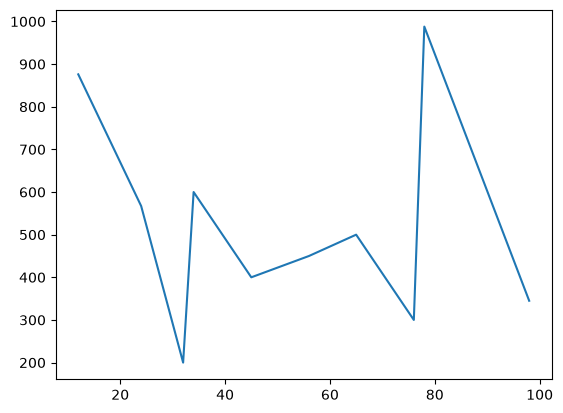

In [21]:
# line graph
plt.plot(sort_age['Age'],sort_age['Salary'])
plt.show()


### Bar Chart: Sorted Relationship (Age vs Salary)
Visualizing salaries across age cohorts using a vertical bar chart with sorted index alignment.

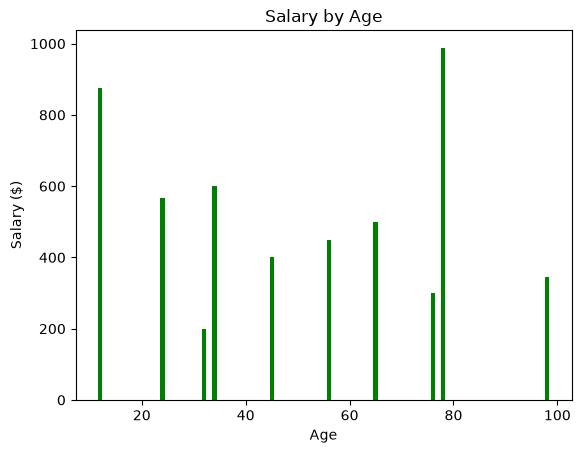

In [22]:
# bar chart
plt.bar(sort_age["Age"], sort_age['Salary'], color="green")
plt.title("Salary by Age")
plt.xlabel("Age")
plt.ylabel("Salary ($)")
plt.show()

## 7. Multi-Category Distribution Analysis (Grouped Box Plots)
Comparing numerical distributions (`Salary`) across multiple categorical levels (`Dept`) using side-by-side box plots.

> [!NOTE]
> Use `tick_labels=[...]` (Matplotlib 3.9+) or `labels=[...]` (earlier versions) to label category ticks on the x-axis.

In [23]:
# Numerical and categorical
It_dep = df[df['Dept']=="IT"] [ "Salary"]
It_dep

0    200
5    450
Name: Salary, dtype: int64

In [24]:
man_dep = df[df['Dept']=="Management"] [ "Salary"]
man_dep

1    400
6    988
Name: Salary, dtype: int64

In [25]:
law_dep = df[df['Dept']=="Law"] [ "Salary"]
law_dep

2    500
7    345
Name: Salary, dtype: int64

In [26]:
bus_dep = df[df['Dept']=="Business"] [ "Salary"]
bus_dep

3    300
8    876
Name: Salary, dtype: int64

In [27]:
mar_dep = df[df['Dept']=="Marketing"] [ "Salary"]
mar_dep

4    600
9    567
Name: Salary, dtype: int64

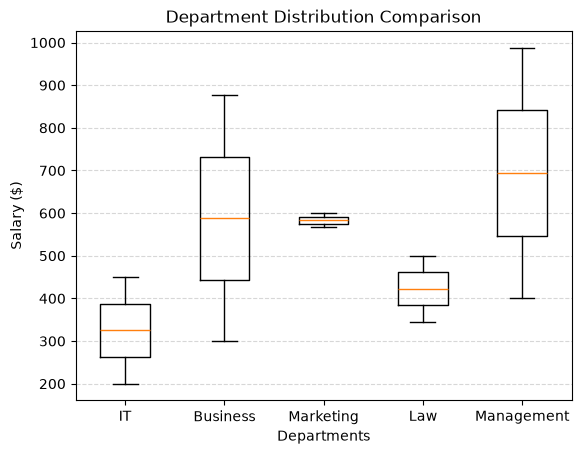

In [28]:
# Grouped box plot with category tick labels
plt.boxplot(
    [It_dep, bus_dep, mar_dep, law_dep, man_dep],
    tick_labels=["IT", "Business", "Marketing", "Law", "Management"]
)
plt.title("Department Distribution Comparison")
plt.xlabel("Departments")
plt.ylabel("Salary ($)")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

## 8. Aggregated Category Analysis (GroupBy + Pie Chart)
Aggregating numerical metrics by department (`df.groupby('Dept')['Salary'].sum()`) and visualizing proportional budget shares.

In [29]:
salary_by_dept=df.groupby("Dept")['Salary'].sum()
salary_by_dept

Dept
Business      1176
IT             650
Law            845
Management    1388
Marketing     1167
Name: Salary, dtype: int64

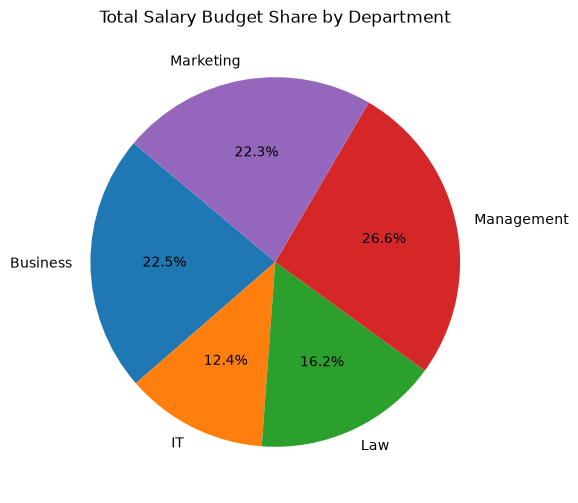

In [30]:
# Pie chart with formatted percentage labels
plt.figure(figsize=(6, 6))
plt.pie(
    salary_by_dept,
    labels=salary_by_dept.index,
    autopct="%1.1f%%",
    startangle=140
)
plt.title("Total Salary Budget Share by Department")
plt.show()

## 9. Multivariate Visualizations (2 Numerical + 1 Categorical Hue)
Mapping categories to distinct colors to visualize 3 dimensions ($X$ = Age, $Y$ = Salary, Color = Dept) on a 2D plane with an annotated legend.

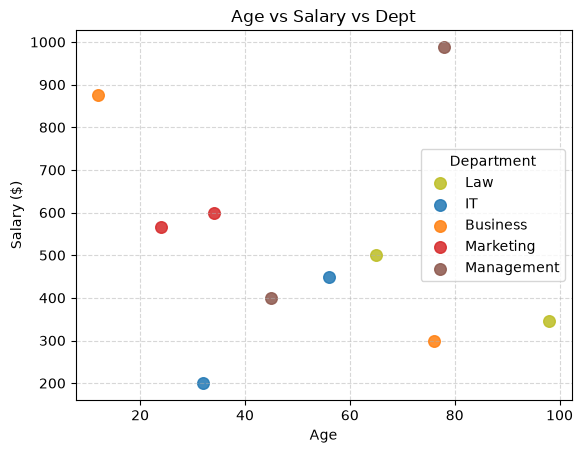

In [31]:
# 2 numeric variables and 1 categorical variable (Hue)
colors = {
    "Law": "#bcbd22",
    "IT": "#1f77b4",
    "Business": "#ff7f0e",
    "Marketing": "#d62728",
    "Management": "#8c564b"
}

for dept, color in colors.items():
    data = df[df["Dept"] == dept]
    plt.scatter(
        data["Age"],
        data["Salary"],
        color=color,
        label=dept,
        s=70,
        alpha=0.85
    )

plt.xlabel("Age")
plt.ylabel("Salary ($)")
plt.title("Age vs Salary vs Dept")
plt.legend(title="Department")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 10. The Object-Oriented (OO) API & Subplots Grid
Using `plt.subplots()` to construct a multi-panel dashboard where each `Axes` object is individually styled and formatted.

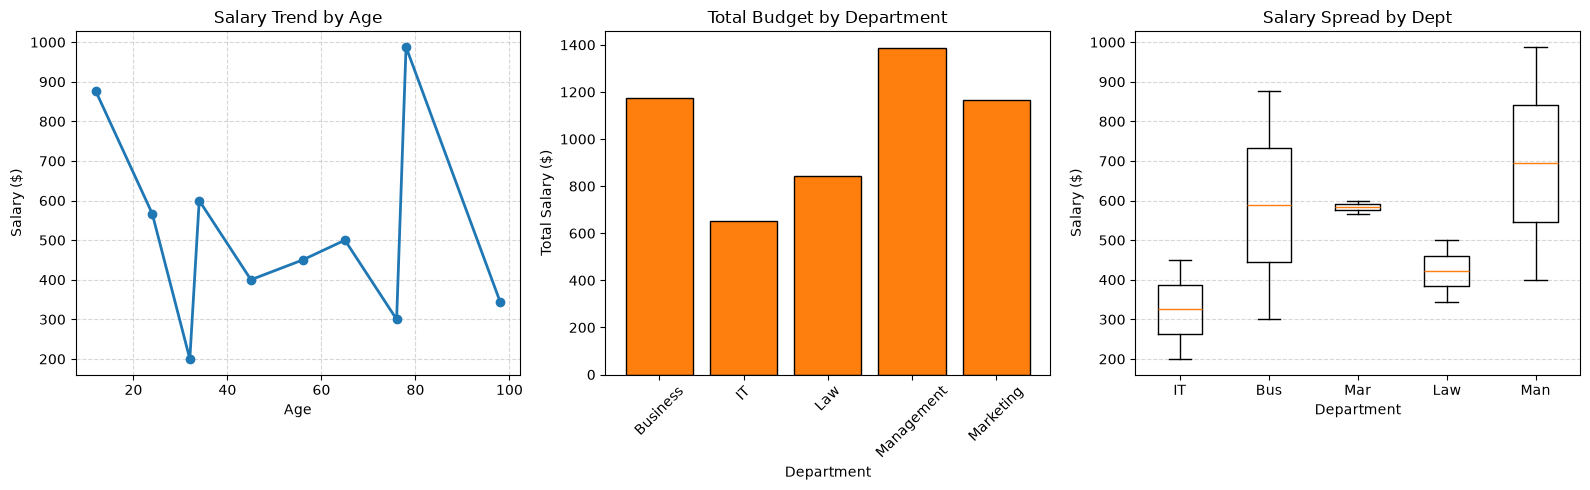

In [32]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

# Subplot 0: Line plot of Salary trend by Age
axs[0].plot(sort_age['Age'], sort_age['Salary'], color='#1f77b4', marker='o', linewidth=2)
axs[0].set_title('Salary Trend by Age')
axs[0].set_xlabel('Age')
axs[0].set_ylabel('Salary ($)')
axs[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 1: Bar chart of Total Salary by Department
axs[1].bar(salary_by_dept.index, salary_by_dept.values, color='#ff7f0e', edgecolor='black')
axs[1].set_title('Total Budget by Department')
axs[1].set_xlabel('Department')
axs[1].set_ylabel('Total Salary ($)')
axs[1].tick_params(axis='x', rotation=45)

# Subplot 2: Grouped box plot of Salary distribution by Department
axs[2].boxplot([It_dep, bus_dep, mar_dep, law_dep, man_dep], tick_labels=["IT", "Bus", "Mar", "Law", "Man"])
axs[2].set_title('Salary Spread by Dept')
axs[2].set_xlabel('Department')
axs[2].set_ylabel('Salary ($)')
axs[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()